In [11]:
import pyroomacoustics as pra
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm
from scipy.signal import stft

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code")  # folder containing HATS_functions.py

from HATS_functions import gcc_phat, corr_to_itd

angles = ["0", "45", "90", "135", "180", "225", "270", "315"]
PathToFiles = "../Audio_Files/Mic_Array/Horizontal"

num_mics = 7
angle_increment = 360/num_mics
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-270.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")

In [12]:
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]

positions = [[0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([r*np.cos(theta), r*np.sin(theta)])

mic_positions = np.array(positions).T

In [13]:
import pyroomacoustics as pra
import numpy as np
import soundfile as sf

# Mic positions — centre + 6 around the circle
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]

positions = [[0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([r*np.cos(theta), r*np.sin(theta)])

mic_positions = np.array(positions).T  # shape (2, 7)

# Load all 7 mic signals
source_angle = '45'
signals = []
for i in range(7):
    data, fs = sf.read(recordings[source_angle][str(i)])
    if data.ndim > 1:
        data = data.mean(axis=1)
    signals.append(data)

min_len = min(len(s) for s in signals)
signals = np.stack([s[:min_len] for s in signals])

# STFT — pra expects (n_samples, n_channels)
nfft = 256
hop = nfft // 2
X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
X = X.transpose(2, 1, 0)  # → (n_mics, n_freq, n_frames)

# SRP-PHAT
doa = pra.doa.algorithms['MUSIC'](mic_positions, fs, nfft, c=343, num_src=1)
doa.locate_sources(X)

estimated_deg = np.degrees(doa.azimuth_recon[0])
print(f"Source angle:    {source_angle}°")
print(f"Estimated DOA:   {estimated_deg:.1f}°")
print(f"Error:           {estimated_deg - float(source_angle):.1f}°")

Source angle:    45°
Estimated DOA:   52.0°
Error:           7.0°


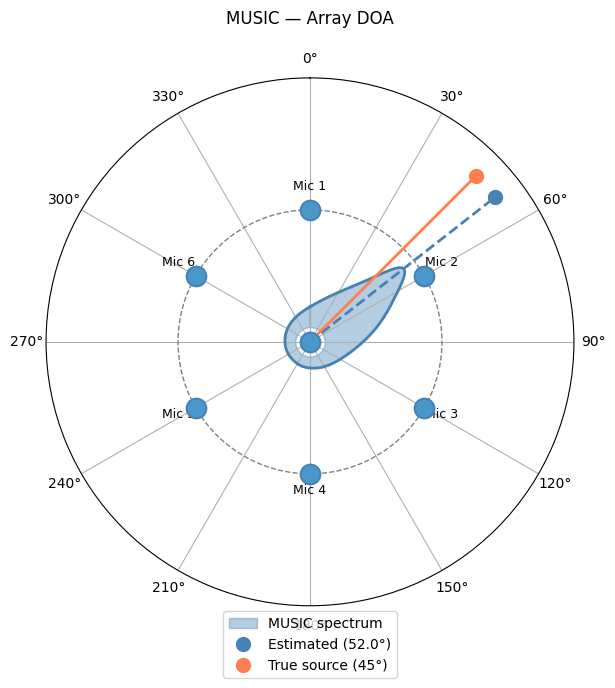

In [14]:
import matplotlib.cm as cm

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

mic_angles_deg = [0, 60, 120, 180, 240, 300]
mic_angles_rad = np.radians(mic_angles_deg)
mic_r = 0.045

# Plain mic markers (no scores now — beamformer gives a continuous output)
for a in mic_angles_rad:
    ax.scatter(a, mic_r, s=200, color=cm.Blues(0.6), zorder=5,
               edgecolors='steelblue', linewidths=1.5)
ax.scatter(0, 0, s=200, color=cm.Blues(0.6), zorder=5,
           edgecolors='steelblue', linewidths=1.5)

for a, label in zip(mic_angles_rad, range(1, 7)):
    ax.annotate(f'Mic {label}', (a, mic_r*1.15), ha='center', fontsize=9)

# Array boundary circle
circle_theta = np.linspace(0, 2*np.pi, 100)
ax.plot(circle_theta, [mic_r]*100, color='gray', linestyle='--', linewidth=1)

# SRP-PHAT spatial spectrum — scale into a thin annular band beyond the array
azimuth = doa.grid.azimuth
spectrum = doa.grid.values
spectrum_norm = spectrum / spectrum.max()

spectrum_r_min = 0.005
spectrum_r_max = mic_r * 0.9
spectrum_r = spectrum_r_min + (spectrum_r_max - spectrum_r_min) * spectrum_norm

ax.fill_between(azimuth, spectrum_r_min, spectrum_r, alpha=0.4, color='steelblue', 
                label='MUSIC spectrum')
ax.plot(azimuth, spectrum_r, color='steelblue', linewidth=2)

# Estimated DOA
estimated_rad = doa.azimuth_recon[0]
estimated_deg = np.degrees(estimated_rad)

ax.plot([estimated_rad, estimated_rad], [0, 0.08], color='steelblue', linestyle='--', 
        linewidth=2)
ax.plot(estimated_rad, 0.08, 'o', color='steelblue', markersize=10, 
        label=f'Estimated ({estimated_deg:.1f}°)')

# True source
source_angle_deg = 45  # change to your actual source angle
source_angle_rad = np.radians(source_angle_deg)
ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10, 
        label=f'True source ({source_angle_deg}°)')

ax.set_ylim(0, 0.09)
ax.set_rticks([])
ax.set_thetagrids(np.arange(0, 360, 30), labels=[f'{a}°' for a in np.arange(0, 360, 30)])
ax.set_title('MUSIC — Array DOA', pad=20)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

MUSIC for 0°...


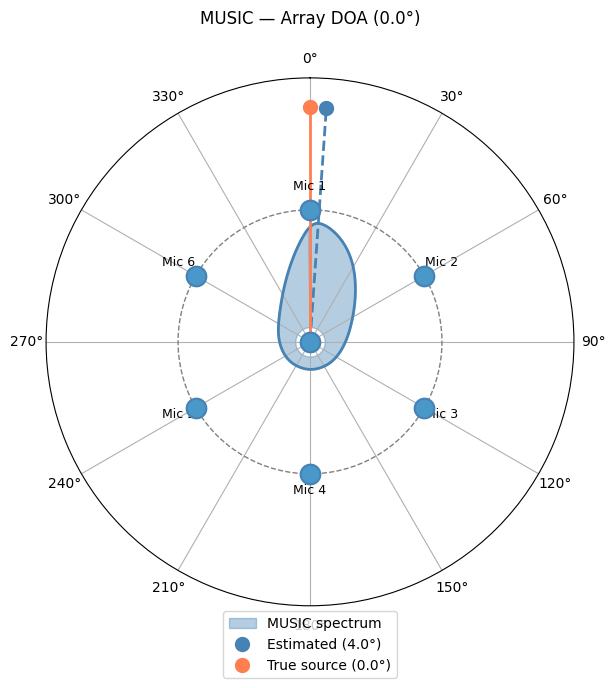

MUSIC for 45°...


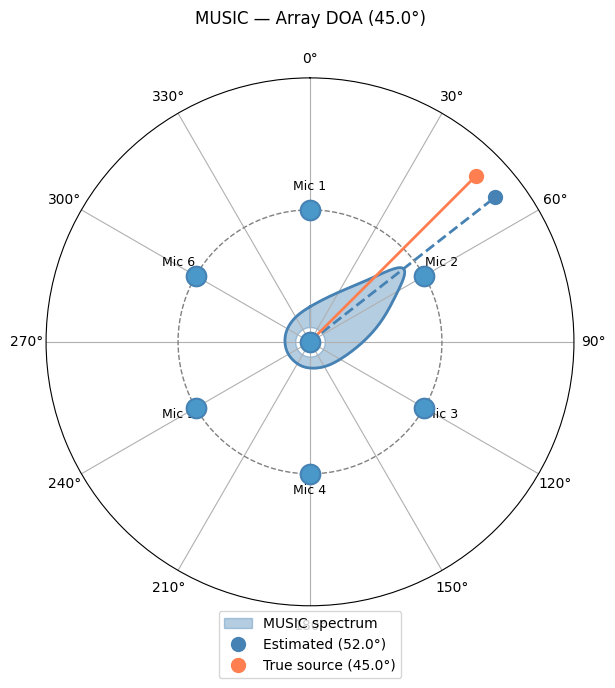

MUSIC for 90°...


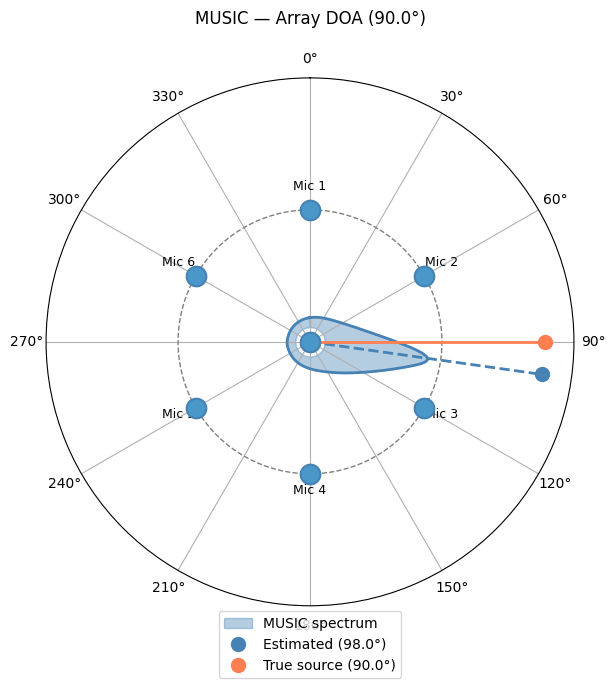

MUSIC for 135°...


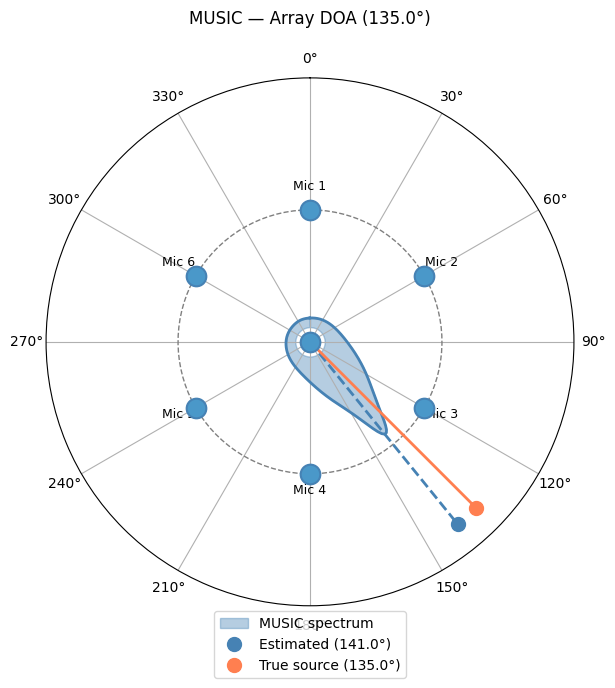

MUSIC for 180°...


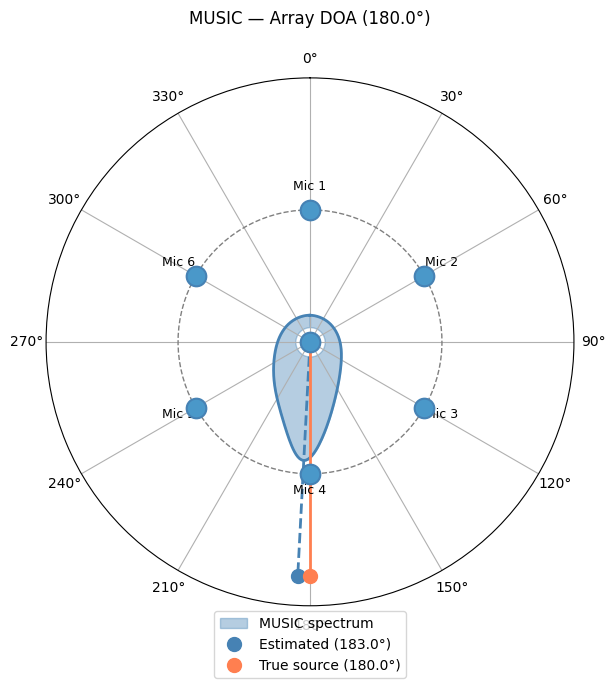

MUSIC for 225°...


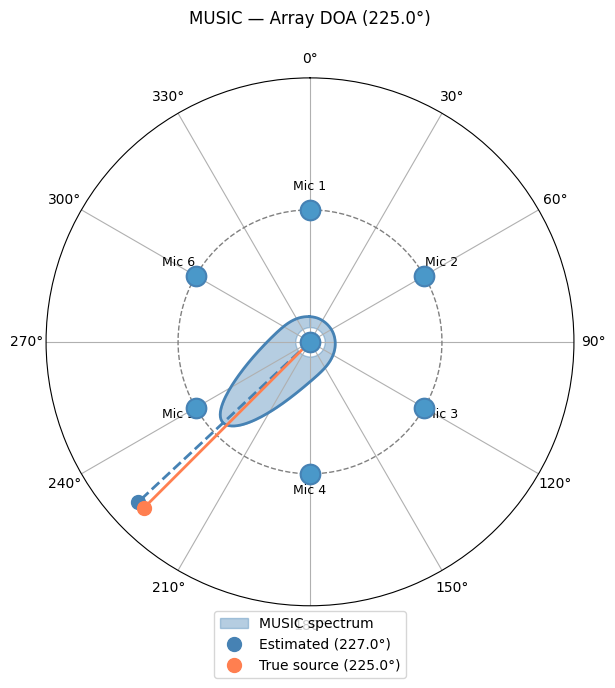

MUSIC for 270°...


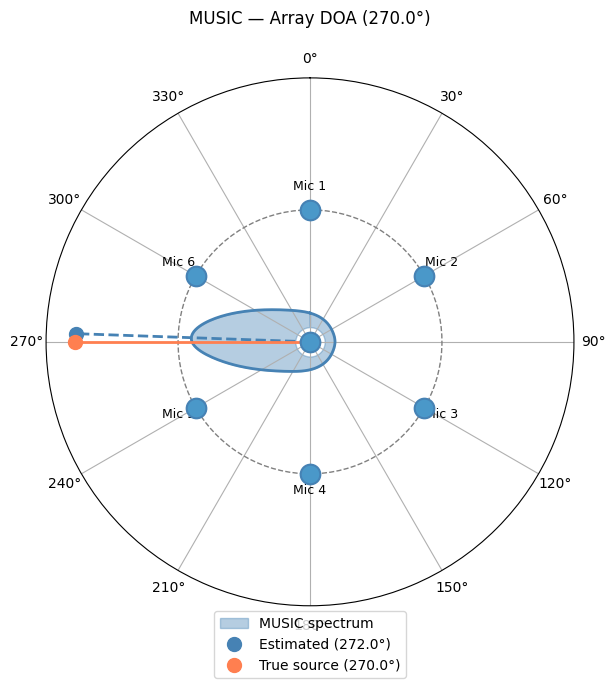

MUSIC for 315°...


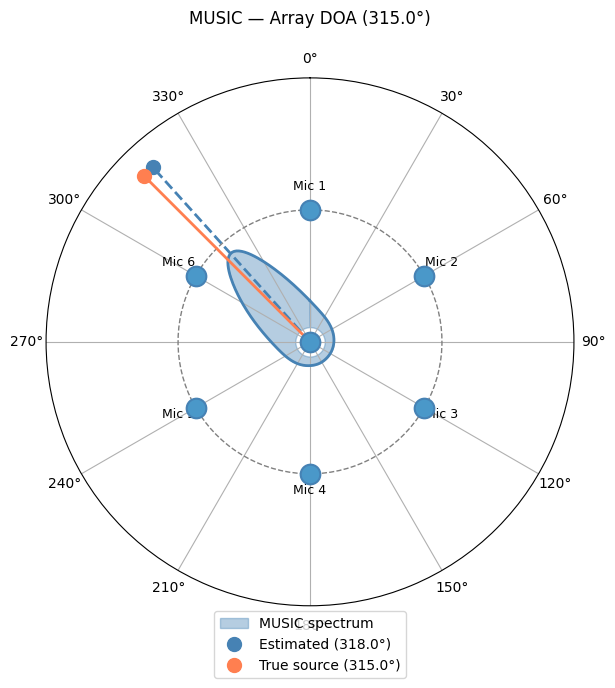

In [15]:
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')
    
def plot_music_doa(doa, true_source_deg, name):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    # Mic markers
    for a in mic_angles_rad:
        ax.scatter(a, mic_r, s=200, color=cm.Blues(0.6), zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
    ax.scatter(0, 0, s=200, color=cm.Blues(0.6), zorder=5,
               edgecolors='steelblue', linewidths=1.5)

    for a, label in zip(mic_angles_rad, range(1, 7)):
        ax.annotate(f'Mic {label}', (a, mic_r * 1.15), ha='center', fontsize=9)

    # Array boundary
    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # MUSIC spectrum as annular band
    azimuth = doa.grid.azimuth
    spectrum = doa.grid.values
    spectrum_norm = spectrum / spectrum.max()

    spectrum_r_min = 0.005
    spectrum_r_max = mic_r * 0.9
    spectrum_r = spectrum_r_min + (spectrum_r_max - spectrum_r_min) * spectrum_norm

    ax.fill_between(azimuth, spectrum_r_min, spectrum_r, alpha=0.4,
                    color='steelblue', label='MUSIC spectrum')
    ax.plot(azimuth, spectrum_r, color='steelblue', linewidth=2)

    # Estimated DOA
    estimated_rad = doa.azimuth_recon[0]
    estimated_deg = np.degrees(estimated_rad)
    ax.plot([estimated_rad, estimated_rad], [0, 0.08], color='steelblue',
            linestyle='--', linewidth=2)
    ax.plot(estimated_rad, 0.08, 'o', color='steelblue', markersize=10,
            label=f'Estimated ({estimated_deg:.1f}°)')

    # True source
    source_angle_rad = np.radians(true_source_deg)
    ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
    ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'MUSIC — Array DOA ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15))
    plt.tight_layout()

    save_fig(fig, name)
    plt.show()
    plt.close(fig)
    
def run_music(source_angle_key):
    signals = []
    for i in range(7):
        data, fs = sf.read(recordings[source_angle_key][str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    doa = pra.doa.algorithms['MUSIC'](mic_positions, fs, nfft, c=343, num_src=1)
    doa.locate_sources(X)
    return doa

# Batch save
music_results = {}
for angle_key in recordings.keys():
    print(f"MUSIC for {angle_key}°...")
    doa = run_music(angle_key)
    music_results[angle_key] = np.degrees(doa.azimuth_recon[0])
    plot_music_doa(doa, float(angle_key), f"music_{angle_key}")


# CSV
import csv
with open(figures_dir / "music_results.csv", 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['source_angle', 'estimated_angle', 'error'])
    for angle_key, est in music_results.items():
        true = float(angle_key)
        writer.writerow([angle_key, f"{est:.2f}", f"{est - true:.2f}"])